In [1]:
from dotenv import load_dotenv
from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper, ArxivAPIWrapper
from langchain_community.tools.tavily_search import TavilySearchResults

load_dotenv()

import os

os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
os.environ["LANGCHAIN_API_KEY"] = os.getenv("LANGCHAIN_API_KEY")
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"





C:\Users\nihar\AppData\Local\Temp\ipykernel_21476\2777741929.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun


In [2]:
api_wrapper_wiki = WikipediaAPIWrapper(
    top_k_results=1,
    doc_content_chars_max=500
)

wiki = WikipediaQueryRun(api_wrapper=api_wrapper_wiki)

tavily = TavilySearchResults()





C:\Users\nihar\AppData\Local\Temp\ipykernel_21476\3875717373.py:8: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily = TavilySearchResults()


In [3]:
### Custom Functions
def multiply(a: int, b: int) -> int:
    """Multiply a and b.

    Args:
        a: first int
        b: second int
    """
    return a * b

# This will be a tool
def add(a: int, b: int) -> int:
    """Adds a and b.

    Args:
        a: first int
        b: second int
    """
    return a + b

def divide(a: int, b: int) -> float:
    """Divide a and b.

    Args:
        a: first int
        b: second int
    """
    return a / b



In [4]:
tools=[wiki,tavily,add,multiply,divide]

In [5]:
from langchain_groq import ChatGroq
from langchain_core.messages import AIMessage,HumanMessage,ToolMessage
from pprint import pprint
from langchain.agents import create_agent

llm_groq = ChatGroq(
    model="qwen/qwen3.8-27b",
    max_tokens = 200

)

llm_with_tools=llm_groq.bind_tools(tools)


In [6]:
## State Schema
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage
from typing import Annotated
from langgraph.graph.message import add_messages
class State(TypedDict):
    messages:Annotated[list[AnyMessage],add_messages]

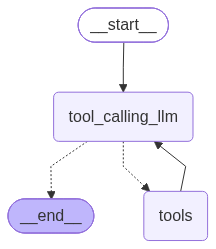

In [7]:
### Entire Chatbot With LangGraph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

### Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

# Build graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
)
builder.add_edge("tools","tool_calling_llm")


graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))


In [8]:
messages=graph.invoke({"messages":HumanMessage(content="Provide me the top 10 recent AI news for MArch 3rd 2025,add 5 plus 5 and then multiply by 10")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Provide me the top 10 recent AI news for MArch 3rd 2025,add 5 plus 5 and then multiply by 10
================================== Ai Message ==================================

I'll help you with both tasks. Let me search for recent AI news from March 3rd, 2025, and perform the math calculation in parallel.
Tool Calls:
  tavily_search_results_json (gj5zpav08)
 Call ID: gj5zpav08
  Args:
    query: top AI news March 3 2025
  add (1qm1ckxgk)
 Call ID: 1qm1ckxgk
  Args:
    a: 5
    b: 5
================================= Tool Message =================================
Name: tavily_search_results_json

[{"title": "March 2025: All AI updates from the past month - SD Times", "url": "https://sdtimes.com/ai/march-2025-all-ai-updates-from-the-past-month", "content": "Skip to content\n\nSD Times\n\nSD Times\n\nLatest News\n\n# March 2025: All AI updates from the past month\n\nByJenna Barron\n\nSoftware companies are c

In [9]:
messages=graph.invoke({"messages":HumanMessage(content="What is machine learning")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

What is machine learning
================================== Ai Message ==================================

Machine learning is a subfield of artificial intelligence (AI) that focuses on building systems that learn from data and improve their performance on a task over time, without being explicitly programmed for every rule.

### Core Concept
Instead of following a fixed set of instructions, a machine learning model is trained on a dataset. It identifies patterns and relationships within that data and uses them to make predictions or decisions about new, unseen data.

### Key Components
1. **Data**: The raw information used for training (e.g., images, text, numbers).
2. **Model**: The algorithm or mathematical structure that learns from the data (e.g., neural networks, decision trees).
3. **Training**: The process where the model adjusts its internal parameters to minimize errors in its predictions.
4. **

### Lets ReWrite abvoe using Agent

In [21]:
llm_groq_agent = ChatGroq(
    model="qwen/qwen3.8-27b",
    max_tokens=200,
    temperature=0
)

tools_agent=[wiki,tavily,add,multiply,divide]


agent = create_agent(
    model=llm_groq_agent,
    tools=tools_agent,
    system_prompt=(
        "You are a helpful AI assistant. "
        "Use Tavily tool for news and Wikipedia for general knowledge. "
        "For calculations, always use the arithmetic tools. "
        "If the user requests multiple calculations, perform "
        "every operation in order using the appropriate tool like add and  multiply tool "
        "Your final response MUST include answers to ALL parts "
        "of the user's request, including the news and "
        "the final numerical calculation result."
    )
)

# display(
#     Image(
#         agent.get_graph().draw_mermaid_png()
#     )
# )


# ==========================================
# 9. INVOKE THE AGENT
# ==========================================

result = agent.invoke({
    "messages": [{
        "role": "user",
        "content": (
            "Provide me the top one recent AI news for MArch 3rd 2025,add 5 plus 5 and then multiply by 10"
        )
    }]
})

print(result["messages"][-1].content)


# ==========================================
# 10. PRINT ALL MESSAGES
# ==========================================

# for message in result["messages"]:
#    message.pretty_print()


Here are the results for all three of your requests:

## 📰 Top AI News for March 3rd, 2025

**Google releases its reasoning model Gemini 2.5, calling it its "most intelligent AI model" yet.**

Building on its first reasoning model (Gemini 2.0 Flash Thinking), Gemini 2.5 features a better base model and improved post-training. In its announcement, Google revealed that all of its future AI models will have reasoning capabilities built in.

*(Other notable stories from that week included Microsoft unveiling a new voice-activated assistant for doctors, and the U.S. Copyright Office releasing Part 2 of its AI report on "copyrightability.")*

## 🧮 Calculations

1. **5 + 5 = 10**
2. **10 × 10 = 100**

**Final result: 100**


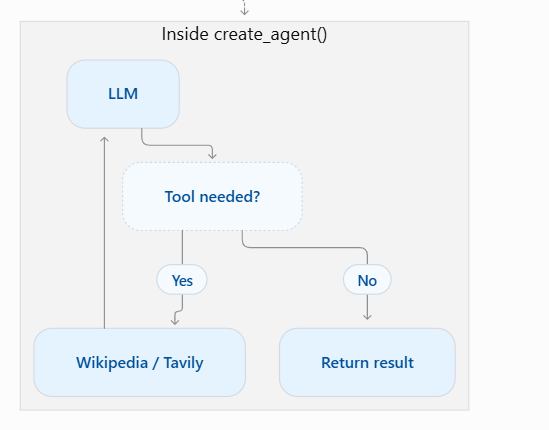

### Create agent if multiple nodes

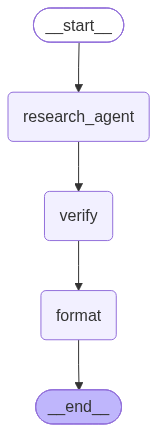

The text contains **no unsupported claims** and exhibits **low uncertainty**. All statements are standard, widely accepted definitions of Machine Learning, and the use of definitive language is appropriate for describing these established concepts.


In [ ]:

from typing_extensions import TypedDict
from langchain.agents import create_agent
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import HumanMessage
from IPython.display import Image, display

# STEP 1: Create research agent
research_agent = create_agent(
    model=llm_groq_agent,
    tools=tools_agent,
    system_prompt=(
        "You are a research assistant. "
        "Use available tools to research questions. "
        "Do not invent facts."
    )
)

# STEP 2: Define shared state
class WorkflowState(TypedDict):
    question: str
    research_answer: str
    verified_answer: str
    final_answer: str

# STEP 3: Node 1 - Run agent
def research_node(state: WorkflowState):
    result = research_agent.invoke({
        "messages": [
            HumanMessage(content=state["question"])
        ]
    })

    return {
        "research_answer": result["messages"][-1].content
    }


def verify_node(state: WorkflowState):
    response = llm_groq_agent.invoke(
        "You are an answer reviewer.\n"
        "Review the following answer for unsupported claims "
        "and misleading certainty.\n"
        "If it is acceptable, return the ORIGINAL ANSWER unchanged.\n"
        "If it needs correction, return the CORRECTED ANSWER.\n"
        "Do not return a review, evaluation, or explanation.\n\n"
        f"Answer:\n{state['research_answer']}"
    )

    return {
        "verified_answer": response.content
    }


# STEP 5: Node 3 - Format final answer

def format_node(state: WorkflowState):
    response = llm_groq_agent.invoke(
        "Format the following answer clearly for the user. "
        "Preserve the factual content. "
        "Do not add commentary about verification.\n\n"
        f"{state['verified_answer']}"
    )

    return {
        "final_answer": response.content
    }


# STEP 6: Build parent graph
builder = StateGraph(WorkflowState)

builder.add_node("research_agent", research_node)
builder.add_node("verify", verify_node)
builder.add_node("format", format_node)

# STEP 7: Connect nodes
builder.add_edge(START, "research_agent")
builder.add_edge("research_agent", "verify")
builder.add_edge("verify", "format")
builder.add_edge("format", END)

# STEP 8: Compile graph
graph = builder.compile()

# STEP 9: Visualize
display(Image(graph.get_graph().draw_mermaid_png()))

# STEP 10: Invoke entire workflow
result = graph.invoke({
    "question": "What is machine learning?",
    "research_answer": "",
    "verified_answer": "",
    "final_answer": ""
})

print("\nRESEARCH ANSWER:\n", result["research_answer"])
print("\nVERIFIED ANSWER:\n", result["verified_answer"])
print("\nFINAL ANSWER:\n", result["final_answer"])


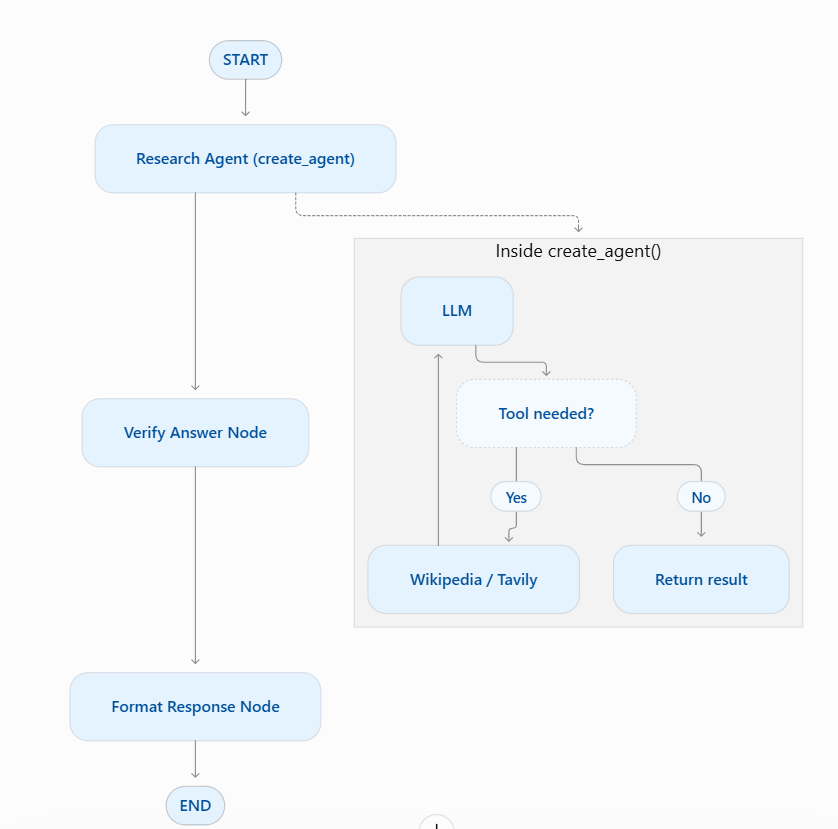